# 🤖 Comprehensive Scikit-Learn Classifier Comparison & Hyperparameter Tuning Pipeline

This notebook demonstrates how to load a custom dataset from a CSV file, preprocess features, cross-evaluate multiple popular Scikit-learn algorithms, and perform automated **Hyperparameter Tuning** via `GridSearchCV` on the best performing model.

https://share.google/aimode/3tJARxDU6hoZi39Xw

### 1. Import Dependencies

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

import sqlite3

In [2]:
# db_path = '/home/aubrey/Desktop/Efate2025/Efate2025B.db'

# conn = sqlite3.connect(db_path)
# conn.enable_load_extension(True)
# conn.load_extension('mod_spatialite')

# sql = '''  
# SELECT tree_id, image_id, confidence, pixel_count, tree_class, ST_AsBinary(tree_poly) AS tree_poly_wkt
# FROM v_trees 
# WHERE tree_class="alive" 
# ORDER BY RANDOM() 
# LIMIT 50
# '''
# df1 = pd.read_sql_query(sql, conn)

# sql = '''  
# SELECT tree_id, image_id, confidence, pixel_count, tree_class, ST_AsBinary(tree_poly) AS tree_poly_wkt
# FROM v_trees 
# WHERE tree_class="dead" 
# ORDER BY RANDOM() 
# LIMIT 50
# '''
# df2 = pd.read_sql_query(sql, conn)

# df = pd.concat([df1, df2], ignore_index=True)
# df

In [3]:
from shapely import wkb
from icecream import ic
import cv2

# Open database
db_path = '/home/aubrey/Desktop/Efate2025/Efate2025B.db'
conn = sqlite3.connect(db_path)  
conn.row_factory = sqlite3.Row  # Enable named column access 
conn.enable_load_extension(True)
conn.load_extension('mod_spatialite')
cursor = conn.cursor()

# get random live tree records and create a csv file
sql = '''  
SELECT tree_id, image_id, confidence, pixel_count, tree_class, ST_AsBinary(tree_poly) AS tree_poly_bin
FROM v_trees 
WHERE tree_class="alive" 
ORDER BY RANDOM() 
LIMIT 100
'''
s = 'tree_id,image_id,confidence,pixel_count,tree_class,h1,h2,h3,h4,h5,h6,h7\n' # csv header
rows = cursor.execute(sql).fetchall()
for row in rows:
    poly = wkb.loads(row['tree_poly_bin']) 
    exterior_coords = np.array(poly.exterior.coords, dtype=np.int32)
    exterior_coords = np.abs(exterior_coords)  # Ensure all coordinates are positive
    moments = cv2.moments(exterior_coords)
    hu_moments = cv2.HuMoments(moments).flatten()
    lhus = [-1.0 * np.sign(m) * np.log10(np.abs(m)) if m != 0 else 0.0 for m in hu_moments]
    s += f'{row["tree_id"]},{row["image_id"]},{row["confidence"]},{row["pixel_count"]},{row["tree_class"]}'  
    for lhu in lhus:
        s += f',{lhu:.4f}'
    s += '\n'
with open('tree_shapes_training_set.csv', 'w', encoding='utf-8') as f:
    f.write(s)
    
# get random "dead" tree records and append to csv file
sql = '''  
SELECT tree_id, image_id, confidence, pixel_count, tree_class, ST_AsBinary(tree_poly) AS tree_poly_bin
FROM v_trees 
WHERE tree_class="dead" 
ORDER BY RANDOM() 
LIMIT 100
'''
s = ''
rows = cursor.execute(sql).fetchall()
for row in rows:
    poly = wkb.loads(row['tree_poly_bin']) 
    exterior_coords = np.array(poly.exterior.coords, dtype=np.int32)
    exterior_coords = np.abs(exterior_coords)  # Ensure all coordinates are positive
    moments = cv2.moments(exterior_coords)
    hu_moments = cv2.HuMoments(moments).flatten()
    lhus = [-1.0 * np.sign(m) * np.log10(np.abs(m)) if m != 0 else 0.0 for m in hu_moments]
    s += f'{row["tree_id"]},{row["image_id"]},{row["confidence"]},{row["pixel_count"]},{row["tree_class"]}'  
    for lhu in lhus:
        s += f',{lhu:.4f}'
    s += '\n'
with open('tree_shapes_training_set.csv', 'a', encoding='utf-8') as f:
    f.write(s)
    
conn.close()

### 2. Configure File Path & Target Column
Change the values below to point to your custom CSV file and target label.

In [4]:
# CREATE A DUMMY CSV FOR DEMONSTRATION PURPOSES
# You can safely delete these 4 lines below once you supply your own dataset
# from sklearn.datasets import make_classification
# X_dummy, y_dummy = make_classification(n_samples=500, n_features=6, n_informative=4, n_classes=3, random_state=42)
# dummy_df = pd.DataFrame(X_dummy, columns=[f'feature_{i}' for i in range(6)])
# dummy_df['target_label'] = y_dummy
# dummy_df.to_csv('my_dataset.csv', index=False)

# CONFIGURATION
CSV_PATH = 'tree_shapes_training_set.csv'       # Path to your custom dataset
TARGET_COLUMN = 'tree_class'   # Name of the column you want to predict

### 3. Load and Preprocess Data

In [5]:
# Load data
df = pd.read_csv(CSV_PATH)
print(f"Dataset loaded successfully. Shape: {df.shape}")

# Separate features and target
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

# Encode categorical target labels if they are strings
if y.dtype == 'object' or isinstance(y.iloc[0], str):
    le = LabelEncoder()
    y = le.fit_transform(y)
    print(f"Encoded target categories: {dict(zip(le.classes_, range(len(le.classes_))))}")

# Split into training and testing sets (stratified to protect class ratios)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Standardize features (vital for distance-based models like KNN and SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Data preprocessed and scaled.")

Dataset loaded successfully. Shape: (200, 12)
Encoded target categories: {'alive': 0, 'dead': 1}
Data preprocessed and scaled.


### 4. Direct Baseline Comparison
Train several popular classifiers with their default settings to identify the top contenders.

In [6]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42)
}

baseline_results = []

for name, model in baseline_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    # Using macro averaging for robust tracking across multiclass or imbalanced settings
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

df_comparison = pd.DataFrame(baseline_results).set_index("Model").sort_values(by="F1-Score (Macro)", ascending=False)
df_comparison

,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
Model,,,,
Random Forest,0.98,0.980769,0.98,0.979992
Gradient Boosting,0.94,0.946429,0.94,0.939783
Logistic Regression,0.92,0.931034,0.92,0.919485
SVM,0.86,0.890625,0.86,0.857201
KNN,0.80,0.807882,0.80,0.798712


### 5. Plot the Comparison Matrix

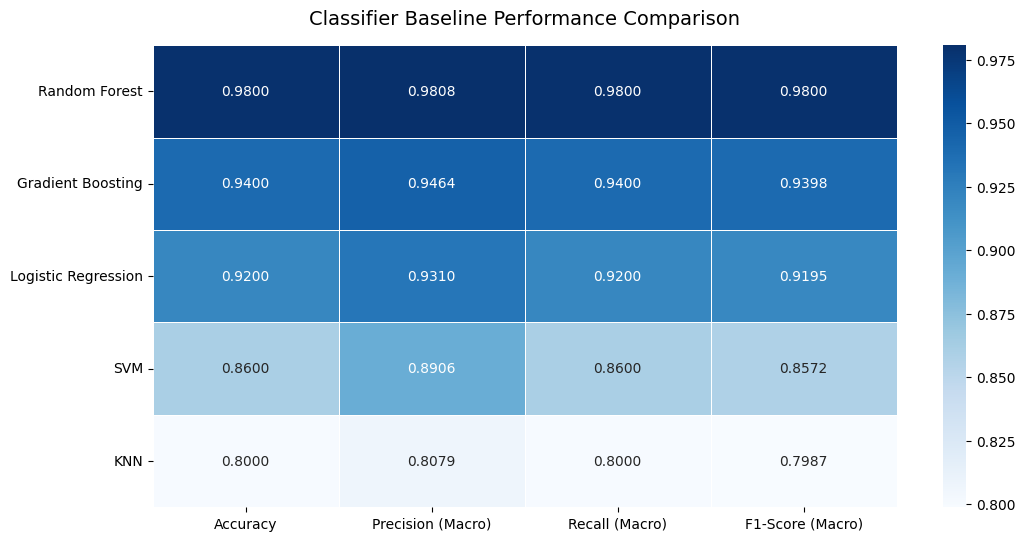

In [7]:
plt.figure(figsize=(12, 6))
sns.heatmap(df_comparison, annot=True, cmap="Blues", fmt=".4f", linewidths=.5)
plt.title("Classifier Baseline Performance Comparison", fontsize=14, pad=15)
plt.ylabel("")
plt.show()

### 6. Automated Hyperparameter Tuning (`GridSearchCV`)
Pick the top baseline algorithm (or manually choose one) to extract extra performance juice using Stratified Cross-Validation optimization.

In [8]:
# Dynamically pick the best baseline model name based on highest F1-score
best_model_name = df_comparison.index[0]
print(f"🎯 Automatically selected candidate for hyperparameter tuning: {best_model_name}\n")

# Define parameters for exploration based on selection
if best_model_name == "Random Forest":
    estimator = RandomForestClassifier(random_state=42)
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10]
    }
elif best_model_name == "SVM":
    estimator = SVC(probability=True, random_state=42)
    param_grid = {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto']
    }
elif best_model_name == "Gradient Boosting":
    estimator = HistGradientBoostingClassifier(random_state=42)
    param_grid = {
        'learning_rate': [0.01, 0.1, 0.2],
        'max_iter': [50, 100, 200],
        'max_depth': [3, 5, None]
    }
elif best_model_name == "Logistic Regression":
    estimator = LogisticRegression(max_iter=1000, random_state=42)
    param_grid = {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'saga']
    }
else: # Defaulting to KNN configuration
    estimator = KNeighborsClassifier()
    param_grid = {
        'n_neighbors': [3, 5, 11, 19],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    }

# Run stratified k-fold cross validation configuration
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(estimator=estimator, param_grid=param_grid, cv=cv_strategy, scoring='f1_macro', n_jobs=-1)

print("🔄 Executing Grid Search... Please wait...")
grid_search.fit(X_train_scaled, y_train)

print("¼ Grid Search Optimization Complete!")
print(f"Best Hyperparameters Found: {grid_search.best_params_}")
print(f"Best Out-of-Fold Macro F1-Score: {grid_search.best_score_:.4f}")

🎯 Automatically selected candidate for hyperparameter tuning: Random Forest

🔄 Executing Grid Search... Please wait...
¼ Grid Search Optimization Complete!
Best Hyperparameters Found: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best Out-of-Fold Macro F1-Score: 0.9666


### 7. Final Model Evaluation
Evaluate the finalized, tuned champion classifier against the held-out test dataset.

In [9]:
tuned_champion = grid_search.best_estimator_
final_predictions = tuned_champion.predict(X_test_scaled)

print(f"=== Final Performance Breakdown for Tuned {best_model_name} ===\n")
print(classification_report(y_test, final_predictions))

=== Final Performance Breakdown for Tuned Random Forest ===

              precision    recall  f1-score   support

           0       0.96      0.96      0.96        25
           1       0.96      0.96      0.96        25

    accuracy                           0.96        50
   macro avg       0.96      0.96      0.96        50
weighted avg       0.96      0.96      0.96        50

